# Human ERβ ligand screening
AIDD8122 final project

Predict pKi from human ERβ binding data in ChEMBL (CHEMBL242). Compare
Morgan and MACCS fingerprints with random forest, support vector
regression and gradient boosting. Use the selected model to rank the
uploaded drug library for docking.

## 1. Settings

In [1]:
from pathlib import Path

SEED = 42
TARGET_ID = "CHEMBL242"
TEST_FRACTION = 0.20
MORGAN_RADIUS = 2
MORGAN_BITS = 2048
MORGAN_CHIRALITY = True
LOW_SIMILARITY = 0.40  # Nearest-neighbor Morgan Tanimoto flag
DOCKING_COUNT = 20
CANDIDATE_CSV = Path("drugbank_fda approved drug.csv")
INPUT_DIR = Path("er_beta_inputs")

if not CANDIDATE_CSV.is_file():
    raise FileNotFoundError(
        f"Upload {CANDIDATE_CSV.name} in Colab's Files panel, then rerun this cell. "
        f"Current path: {CANDIDATE_CSV}"
    )

In [2]:
from importlib.util import find_spec
import subprocess
import sys

if find_spec("rdkit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit==2025.9.2"])

import json
from datetime import datetime, timezone
from functools import lru_cache
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from IPython.display import display
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    KFold,
    cross_val_score,
    train_test_split,
)
from sklearn.svm import SVR

INPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path("er_beta_ml_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True)
VERSIONS = {
    "python": sys.version.split()[0],
    "rdkit": rdBase.rdkitVersion,
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
}


def save_json(path, payload):
    temporary_path = path.with_suffix(".tmp")
    temporary_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    temporary_path.replace(path)


def save_table(frame, name):
    frame.to_csv(RUN_DIR / name, index=False)


print("Results folder:", RUN_DIR)
print("Package versions:", VERSIONS)

Results folder: er_beta_ml_results/20261115T041128788812Z
Package versions: {'python': '3.11.18', 'rdkit': '2026.09.2', 'scikit-learn': '1.9.1', 'pandas': '3.0.2', 'numpy': '2.4.6'}


## 2. ChEMBL records

Retrieve Ki measurements for CHEMBL242. The local snapshot stores the
ChEMBL release, query and raw records.

[ChEMBL web services](https://chembl.gitbook.io/chembl-interface-documentation/web-services/chembl-data-web-services)

In [3]:
CHEMBL_API = "https://www.ebi.ac.uk/chembl/api/data/"
session = requests.Session()
retries = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retries))


def fetch_json(url, params=None):
    try:
        response = session.get(url, params=params, timeout=(15, 90))
        response.raise_for_status()
        return response.json()
    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError(
            f"Could not retrieve public data from {url}. Retry this cell."
        ) from exc


def chembl_records(resource, field, params):
    records = []
    url = urljoin(CHEMBL_API, resource + ".json")
    params = {**params, "limit": 1000}
    expected_total = None
    while url:
        page = fetch_json(url, params=params)
        records.extend(page[field])
        metadata = page["page_meta"]
        if expected_total is None:
            expected_total = metadata["total_count"]
        next_page = metadata["next"]
        url = urljoin(url, next_page) if next_page else None
        params = None
    if len(records) != expected_total:
        raise RuntimeError(
            f"ChEMBL returned {len(records)} of {expected_total} {field}. Retry the download."
        )
    return records


def use_snapshot(filename, retrieve):
    path = INPUT_DIR / filename
    if not path.is_file():
        save_json(path, retrieve())
    else:
        print("Using snapshot:", path)
    return json.loads(path.read_text(encoding="utf-8"))


ACTIVITY_QUERY = {
    "target_chembl_id": TARGET_ID,
    "standard_type": "Ki",
    "order_by": "activity_id",
}


def download_chembl():
    print("Downloading ChEMBL Ki records.")
    status = fetch_json(urljoin(CHEMBL_API, "status.json"))
    target = fetch_json(urljoin(CHEMBL_API, f"target/{TARGET_ID}.json"))
    activities = chembl_records("activity", "activities", ACTIVITY_QUERY)
    return {
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "status": status,
        "target": target,
        "activity_query": ACTIVITY_QUERY,
        "activities": activities,
    }


chembl = use_snapshot("chembl242_ki.json", download_chembl)
target = chembl["target"]
if (target["target_chembl_id"], target["organism"], target["target_type"]) != (
    TARGET_ID,
    "Homo sapiens",
    "SINGLE PROTEIN",
):
    raise ValueError("Expected the human single-protein ERβ target CHEMBL242.")

raw = pd.DataFrame(chembl["activities"])
if raw.empty:
    raise ValueError("The snapshot contains no Ki records.")

print("ChEMBL database:", chembl["status"].get("chembl_db_version", chembl["status"]))
print(f"Retrieved {len(raw):,} Ki records across {raw['assay_chembl_id'].nunique():,} assays.")

Using snapshot: er_beta_inputs/chembl242_ki.json
ChEMBL database: ChEMBL_37
Retrieved 1,479 Ki records across 56 assays.


## 3. Ki curation

Keep exact Ki measurements (=) with a finite positive value and a
recognized concentration unit. 
Convert to pKi as 9 − log₁₀(Ki in nM).
Strip salts, canonicalize parent structures and take the median pKi when
multiple measurements map to the same parent. Keep assay IDs to trace
the measurements. The data include Ki values from different assay types
and conditions.

In [4]:
ki_rows = raw["target_chembl_id"].eq(TARGET_ID) & raw["standard_type"].eq("Ki")
activity = raw.loc[ki_rows].copy()

In [5]:
@lru_cache(maxsize=None)
def standardize_smiles(smiles):
    """Return the canonical parent SMILES with stereochemistry."""
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    with rdBase.BlockLogs():
        try:
            mol = Chem.MolFromSmiles(smiles)
            if mol is None:
                return None
            parent = rdMolStandardize.FragmentParent(mol)
            parent = rdMolStandardize.Uncharger().uncharge(parent)
            if parent.GetNumHeavyAtoms() == 0:
                return None
            parent_smiles = Chem.MolToSmiles(parent, canonical=True, isomericSmiles=True)
            # A standardized structure must still parse for fingerprinting.
            return parent_smiles if Chem.MolFromSmiles(parent_smiles) is not None else None
        except (ValueError, RuntimeError):
            return None


def connectivity_key(smiles):
    # Match connectivity when stereochemistry is unspecified.
    return Chem.MolToSmiles(Chem.MolFromSmiles(smiles), isomericSmiles=False)


def scaffold_key(mol):
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol) or "(acyclic)"


def join_ids(values):
    return "|".join(sorted(set(values.dropna().astype(str))))


curation = [{"stage": "ChEMBL ERβ Ki records", "n": len(activity), "unit": "records"}]

eligible = activity.loc[activity["standard_relation"].eq("=")].copy()
curation.append({"stage": "Exact measurements", "n": len(eligible), "unit": "records"})

unit_to_nm = {"pM": 1e-3, "nM": 1.0, "uM": 1e3, "µM": 1e3, "μM": 1e3, "mM": 1e6, "M": 1e9}
value = pd.to_numeric(eligible["standard_value"], errors="coerce")
eligible["ki_nM"] = value * eligible["standard_units"].map(unit_to_nm)
eligible = eligible.loc[np.isfinite(eligible["ki_nM"]) & eligible["ki_nM"].gt(0)].copy()
eligible["pKi"] = 9 - np.log10(eligible["ki_nM"])
curation.append({"stage": "Convertible positive Ki", "n": len(eligible), "unit": "records"})

eligible["smiles"] = eligible["canonical_smiles"].map(standardize_smiles)
eligible = eligible.dropna(subset=["smiles"])
curation.append({"stage": "Valid parent structures", "n": len(eligible), "unit": "records"})

curated = eligible.groupby("smiles", as_index=False).agg(
    pKi=("pKi", "median"),
    n_measurements=("pKi", "size"),
    molecule_chembl_ids=("molecule_chembl_id", join_ids),
    assay_chembl_ids=("assay_chembl_id", join_ids),
)
curated.insert(0, "compound_id", [f"ERB_{i:05d}" for i in range(1, len(curated) + 1)])
curated["scaffold"] = [scaffold_key(Chem.MolFromSmiles(s)) for s in curated["smiles"]]
curation.append({"stage": "Unique parent structures", "n": len(curated), "unit": "compounds"})

display(pd.DataFrame(curation))
if "assay_type" in eligible:
    print(
        "Retained records by ChEMBL assay type:",
        eligible["assay_type"].value_counts().to_dict(),
    )
if len(curated) < 20 or curated["scaffold"].nunique() < 4 or curated["pKi"].nunique() < 2:
    raise ValueError(
        "Too few unique structures, scaffolds or pKi values for model evaluation."
    )

,stage,n,unit
0,ChEMBL ERβ Ki records,1479,records
1,Exact measurements,450,records
2,Convertible positive Ki,450,records
3,Valid parent structures,450,records
4,Unique parent structures,399,compounds


Retained records by ChEMBL assay type: {'B': 436, 'F': 14}


count    399.000
mean       6.945
std        1.335
min        3.524
25%        5.910
50%        6.897
75%        7.802
max       10.602


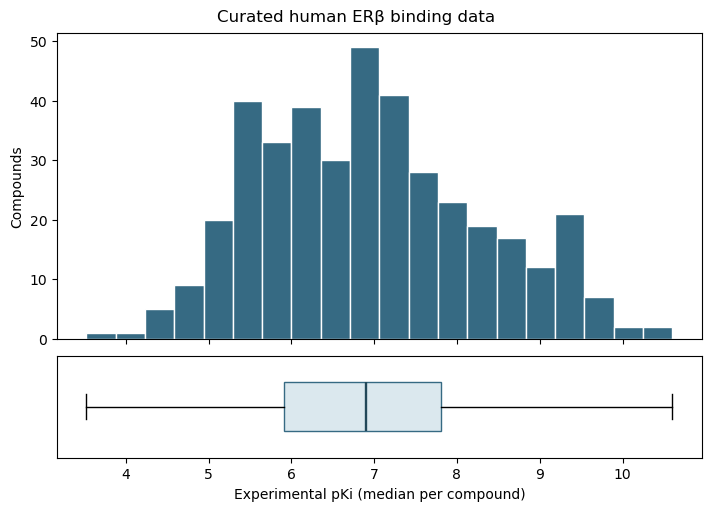

In [6]:
pki = curated["pKi"]
print(pki.describe().round(3).to_string())

fig, (ax_hist, ax_box) = plt.subplots(
    2, 1, sharex=True, figsize=(7.0, 5.0),
    gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True,
)
fig.suptitle("Curated human ERβ binding data")
ax_hist.hist(pki, bins=20, color="#366a83", edgecolor="white")
ax_hist.set_ylabel("Compounds")

ax_box.boxplot(
    pki, vert=False, widths=0.48, whis=1.5, patch_artist=True,
    boxprops={"facecolor": "#dbe8ee", "edgecolor": "#366a83"},
    medianprops={"color": "#234859", "linewidth": 1.7},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none"},
)
ax_box.set_yticks([])
ax_box.set_xlabel("Experimental pKi (median per compound)")
plt.show()
plt.close(fig)


## 4. Fingerprints and holdouts

Compute chiral Morgan fingerprints (radius 2, 2,048 bits) and RDKit MACCS
keys (167 positions, with position 0 unused). Use the same splits for both
representations. The scaffold split keeps Bemis–Murcko groups intact,
with acyclic molecules in a single group. Choose the sampled scaffold
holdout nearest to 20% of the compounds, then draw a random holdout of
the same size.

In [7]:
fingerprinter = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS, fpSize=MORGAN_BITS, includeChirality=MORGAN_CHIRALITY,
)


fingerprint_functions = {
    "Morgan": fingerprinter.GetFingerprint,
    "MACCS": MACCSkeys.GenMACCSKeys,
}


def make_features(smiles_values, fingerprint):
    get_fingerprint = fingerprint_functions[fingerprint]
    fingerprints = [get_fingerprint(Chem.MolFromSmiles(s)) for s in smiles_values]
    matrix = np.zeros((len(fingerprints), fingerprints[0].GetNumBits()), dtype=np.uint8)
    for row, fingerprint in zip(matrix, fingerprints):
        DataStructs.ConvertToNumpyArray(fingerprint, row)
    return matrix, fingerprints


def nearest_reference(query_fps, reference_fps):
    similarities = []
    nearest_indices = []
    for query in query_fps:
        scores = DataStructs.BulkTanimotoSimilarity(query, reference_fps)
        nearest = int(np.argmax(scores))
        nearest_indices.append(nearest)
        similarities.append(scores[nearest])
    return np.asarray(similarities), np.asarray(nearest_indices)


X_morgan, morgan_fingerprints = make_features(curated["smiles"], "Morgan")
X_maccs, _ = make_features(curated["smiles"], "MACCS")
features = {"Morgan": X_morgan, "MACCS": X_maccs}
y = curated["pKi"].to_numpy()
scaffolds = curated["scaffold"].to_numpy()
all_indices = np.arange(len(curated))

group_splitter = GroupShuffleSplit(n_splits=128, test_size=TEST_FRACTION, random_state=SEED)
valid_group_splits = [
    (train, test)
    for train, test in group_splitter.split(X_morgan, groups=scaffolds)
    if len(test) >= 5 and len(train) >= 10 and len(np.unique(scaffolds[train])) >= 3
]
if not valid_group_splits:
    raise ValueError(
        "Could not create a usable scaffold holdout with at least three training scaffolds."
    )
scaffold_train, scaffold_test = min(
    valid_group_splits, key=lambda split: abs(len(split[1]) - TEST_FRACTION * len(curated))
)
random_train, random_test = train_test_split(
    all_indices, test_size=len(scaffold_test), random_state=SEED,
)
splits = {
    "random": (np.sort(random_train), np.sort(random_test)),
    "scaffold": (scaffold_train, scaffold_test),
}

In [8]:
# Summarize the two holdouts for the model comparison.
summary_rows = []
for split_name, (train, test) in splits.items():
    if set(train) & set(test):
        raise RuntimeError(f"Training and test rows overlap in the {split_name} split.")
    shared_scaffolds = set(scaffolds[train]) & set(scaffolds[test])
    if split_name == "scaffold" and shared_scaffolds:
        raise RuntimeError("Scaffold holdout contains training scaffolds.")
    similarity, _ = nearest_reference(
        [morgan_fingerprints[i] for i in test], [morgan_fingerprints[i] for i in train],
    )
    summary_rows.append(
        {
            "split": split_name,
            "n_train": len(train),
            "n_test": len(test),
            "test_fraction": len(test) / len(curated),
            "n_train_scaffolds": len(set(scaffolds[train])),
            "n_test_scaffolds": len(set(scaffolds[test])),
            "n_shared_scaffolds": len(shared_scaffolds),
            "train_pKi_mean": y[train].mean(),
            "train_pKi_sd": y[train].std(ddof=1),
            "test_pKi_mean": y[test].mean(),
            "test_pKi_sd": y[test].std(ddof=1),
            "median_test_to_train_similarity": np.median(similarity),
        }
    )
split_summary = pd.DataFrame(summary_rows)
display(split_summary.round(3))

,split,n_train,n_test,test_fraction,n_train_scaffolds,n_test_scaffolds,n_shared_scaffolds,train_pKi_mean,train_pKi_sd,test_pKi_mean,test_pKi_sd,median_test_to_train_similarity
0,random,319,80,0.201,131,55,28,6.964,1.313,6.866,1.424,0.823
1,scaffold,319,80,0.201,126,32,0,6.781,1.250,7.598,1.464,0.621


## 5. Model comparison

Compare all six fingerprint and regressor combinations. Use the same
training folds within each split. Tune by cross-validation MAE and select
the screening combination by scaffold training CV MAE before evaluating
either holdout.

In [9]:
model_settings = {
    "Random forest": (
        RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
        {"max_features": ["sqrt", 0.25], "min_samples_leaf": [1, 3]},
    ),
    "SVR": (SVR(kernel="rbf", gamma="scale"), {"C": [1, 10, 50], "epsilon": [0.1, 0.3]}),
    "Gradient boosting": (
        GradientBoostingRegressor(n_estimators=100, random_state=SEED),
        {"max_depth": [2, 3], "learning_rate": [0.05, 0.1]},
    ),
}

baseline_key = ("No fingerprint", "Mean baseline")
benchmark_models = {}
for split_name, (train, _) in splits.items():
    X_train, y_train = X_morgan[train], y[train]
    if split_name == "scaffold":
        n_folds = min(5, len(np.unique(scaffolds[train])))
        cv = list(GroupKFold(n_splits=n_folds).split(X_train, groups=scaffolds[train]))
    else:
        cv = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train))

    baseline = DummyRegressor(strategy="mean")
    baseline_mae = -cross_val_score(
        baseline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        error_score="raise",
    ).mean()
    benchmark_models[split_name] = {
        baseline_key: (baseline.fit(X_train, y_train), baseline_mae, {})
    }

    for fingerprint, matrix in features.items():
        print(f"{split_name}: training {fingerprint} models", flush=True)
        for model_name, (estimator, param_grid) in model_settings.items():
            search = GridSearchCV(
                estimator,
                param_grid,
                scoring="neg_mean_absolute_error",
                cv=cv,
                n_jobs=1,
                error_score="raise",
            )
            search.fit(matrix[train], y_train)
            benchmark_models[split_name][fingerprint, model_name] = (
                search.best_estimator_,
                -search.best_score_,
                search.best_params_,
            )

scaffold_models = benchmark_models["scaffold"]
screening_key = min(
    (key for key in scaffold_models if key != baseline_key),
    key=lambda key: scaffold_models[key][1],
)
screening_fingerprint, screen_model_name = screening_key
selected_estimator = scaffold_models[screening_key][0]
print(f"Selected by scaffold training CV MAE: {screening_fingerprint} + {screen_model_name}")

random: training Morgan models
random: training MACCS models
scaffold: training Morgan models
scaffold: training MACCS models
Selected by scaffold training CV MAE: MACCS + Gradient boosting


### Holdout evaluation

Report MAE, RMSE and R² on the same holdout compounds for every
combination within a split. Refit the screening combination on all
curated compounds after evaluation.

In [10]:
metric_rows = []
prediction_tables = []
for split_name, (train, test) in splits.items():
    for key, (estimator, cv_mae, parameters) in benchmark_models[split_name].items():
        fingerprint, model_name = key
        matrix = features.get(fingerprint, X_morgan)  # The mean baseline ignores features.
        pred = estimator.predict(matrix[test])
        metric_rows.append(
            {
                "split": split_name,
                "fingerprint": fingerprint,
                "model": model_name,
                "n_train": len(train),
                "n_test": len(test),
                "training_cv_MAE": cv_mae,
                "test_MAE": mean_absolute_error(y[test], pred),
                "test_RMSE": np.sqrt(mean_squared_error(y[test], pred)),
                "test_R2": r2_score(y[test], pred) if np.ptp(y[test]) > 0 else np.nan,
                "parameters": json.dumps(parameters),
                "screening_model": key == screening_key,
            }
        )
        if key == screening_key:
            prediction_tables.append(
                pd.DataFrame(
                    {"split": split_name, "experimental_pKi": y[test], "predicted_pKi": pred,}
                )
            )

metrics = pd.DataFrame(metric_rows).merge(
    split_summary.drop(columns=["n_train", "n_test"]), on="split", validate="many_to_one"
)
predictions = pd.concat(prediction_tables, ignore_index=True)
save_table(metrics, "model_metrics.csv")
display(
    metrics[
        [
            "split",
            "fingerprint",
            "model",
            "n_test",
            "training_cv_MAE",
            "test_MAE",
            "test_RMSE",
            "test_R2",
            "screening_model",
        ]
    ].round(3)
)

scaffold_metrics = metrics.loc[metrics["split"].eq("scaffold")]
selected_mae = scaffold_metrics.loc[scaffold_metrics["screening_model"], "test_MAE"].iat[0]
baseline_mae = scaffold_metrics.loc[
    scaffold_metrics["model"].eq("Mean baseline"), "test_MAE"
].iat[0]
if selected_mae >= baseline_mae:
    print(
        "Scaffold holdout MAE was at least as high as the baseline. Treat the ranking as exploratory."
    )

,split,fingerprint,model,n_test,training_cv_MAE,test_MAE,test_RMSE,test_R2,screening_model
0,random,No fingerprint,Mean baseline,80,1.068,1.177,1.418,-0.005,False
1,random,Morgan,Random forest,80,0.597,0.600,0.785,0.692,False
2,random,Morgan,SVR,80,0.575,0.626,0.815,0.668,False
3,random,Morgan,Gradient boosting,80,0.597,0.609,0.773,0.701,False
4,random,MACCS,Random forest,80,0.614,0.611,0.795,0.684,False
5,random,MACCS,SVR,80,0.616,0.594,0.812,0.670,False
6,random,MACCS,Gradient boosting,80,0.609,0.576,0.705,0.752,True
7,scaffold,No fingerprint,Mean baseline,80,1.027,1.390,1.668,-0.315,False
8,scaffold,Morgan,Random forest,80,0.586,0.810,1.011,0.517,False
9,scaffold,Morgan,SVR,80,0.625,0.872,1.060,0.469,False


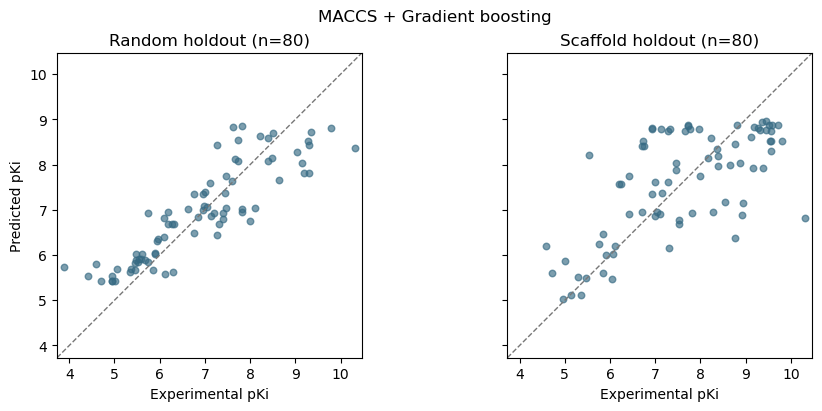

In [11]:
plot_data = predictions
plot_values = plot_data[["experimental_pKi", "predicted_pKi"]].to_numpy()
axis_lo, axis_hi = plot_values.min() - 0.15, plot_values.max() + 0.15
fig, axes = plt.subplots(
    1, 2, figsize=(9, 4), sharex=True, sharey=True, constrained_layout=True
)
for ax, split_name in zip(axes, splits):
    points = plot_data.loc[plot_data["split"].eq(split_name)]
    ax.scatter(
        points["experimental_pKi"], points["predicted_pKi"], s=22, alpha=0.65, color="#366a83"
    )
    ax.plot(
        [axis_lo, axis_hi], [axis_lo, axis_hi], linestyle="--", color="#777777", linewidth=1
    )
    ax.set(
        xlabel="Experimental pKi",
        title=f"{split_name.capitalize()} holdout (n={len(points)})",
        xlim=(axis_lo, axis_hi),
        ylim=(axis_lo, axis_hi),
        aspect="equal",
    )
axes[0].set_ylabel("Predicted pKi")
fig.suptitle(f"{screening_fingerprint} + {screen_model_name}")
fig.savefig(RUN_DIR / "observed_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Refit the chosen model on all curated records for prospective scoring.
screen_model = clone(selected_estimator).fit(features[screening_fingerprint], y)

## 6. Candidate library

Read the uploaded drug library. The loader checks for an Excel workbook
before trying CSV encodings. It extracts Cat/Name/SMILES and
drugbank_id/name/moldb_smiles headers.

In [12]:
def read_library(path):
    with path.open("rb") as stream:
        signature = stream.read(4)
        if signature == b"PK\x03\x04":
            if find_spec("openpyxl") is None:
                subprocess.check_call(
                    [sys.executable, "-m", "pip", "install", "-q", "openpyxl"]
                )
            stream.seek(0)
            return pd.read_excel(stream, dtype=str, engine="openpyxl"), "Excel workbook"

    if signature.startswith((b"\xff\xfe", b"\xfe\xff")):
        return pd.read_csv(path, dtype=str, encoding="utf-16"), "UTF-16 CSV"
    try:
        return pd.read_csv(path, dtype=str, encoding="utf-8-sig"), "UTF-8 CSV"
    except UnicodeDecodeError:
        return pd.read_csv(path, dtype=str, encoding="cp1252"), "Windows-1252 CSV"


library, library_format = read_library(CANDIDATE_CSV)
library.columns = [
    " ".join(column.strip().lower().replace("_", " ").replace("-", " ").split())
    for column in library.columns
]

id_column = next(
    (column for column in ("drugbank id", "cat", "candidate id") if column in library), None,
)
smiles_column = next(
    (column for column in ("smiles", "moldb smiles", "canonical smiles") if column in library),
    None,
)
if id_column is None or smiles_column is None:
    raise ValueError(f"Expected an ID and SMILES column. Found: {', '.join(library.columns)}")

columns = {id_column: "candidate_id", smiles_column: "smiles"}
if "name" in library:
    columns["name"] = "name"
candidate_raw = library[list(columns)].rename(columns=columns)
ids = candidate_raw["candidate_id"].fillna("").str.strip()
if candidate_raw.empty or ids.eq("").any() or not ids.is_unique:
    raise ValueError("The candidate CSV must have a unique, nonblank ID on each row.")
candidate_raw["candidate_id"] = ids

print(f"{CANDIDATE_CSV.name} ({library_format}): {len(candidate_raw):,} compounds")

drugbank_fda approved drug.csv (Excel workbook): 3,182 compounds


### Filter and score candidates

Remove invalid structures, connectivity matches to the retrieved ERβ Ki
records and duplicate parent SMILES. Predict pKi with the selected
representation. Use Morgan fingerprints for the nearest-training
Tanimoto diagnostic in either case. Values below 0.40 flag low similarity.

In [13]:
known_parents = activity["canonical_smiles"].dropna().unique()
known_ki_keys = {
    connectivity_key(parent) for parent in map(standardize_smiles, known_parents) if parent
}

candidates = candidate_raw.assign(smiles=candidate_raw["smiles"].map(standardize_smiles))
valid = candidates.dropna(subset=["smiles"])
known = valid["smiles"].map(connectivity_key).isin(known_ki_keys)
unseen = valid.loc[~known]
candidates = unseen.drop_duplicates(subset="smiles").reset_index(drop=True)
print(
    f"Excluded {len(candidate_raw) - len(valid)} invalid or missing structures, "
    f"{known.sum()} matches to known Ki records and "
    f"{len(unseen) - len(candidates)} duplicate parents."
)
if candidates.empty:
    raise ValueError("No compounds remain after filtering the candidate CSV.")

X_candidates, candidate_fps = make_features(candidates["smiles"], screening_fingerprint)
if screening_fingerprint == "MACCS":
    _, candidate_fps = make_features(candidates["smiles"], "Morgan")
similarity, neighbors = nearest_reference(candidate_fps, morgan_fingerprints)
candidates["predicted_pKi"] = screen_model.predict(X_candidates)
candidates["model"] = screen_model_name
candidates["fingerprint"] = screening_fingerprint
candidates["max_training_tanimoto"] = similarity
candidates["nearest_training_chembl_ids"] = curated.loc[
    neighbors, "molecule_chembl_ids"
].to_numpy()
candidates["low_training_similarity"] = similarity < LOW_SIMILARITY
candidates["scaffold"] = [scaffold_key(Chem.MolFromSmiles(s)) for s in candidates["smiles"]]

ranked = candidates.sort_values(
    ["predicted_pKi", "max_training_tanimoto", "candidate_id"], ascending=[False, False, True]
).reset_index(drop=True)
ranked.insert(0, "ml_rank", np.arange(1, len(ranked) + 1))

save_table(ranked, "candidate_rankings.csv")
print(
    f"Ranked {len(ranked):,} compounds ({ranked['low_training_similarity'].sum():,} below the similarity cutoff)."
)
display(ranked.drop(columns=["smiles", "scaffold", "model", "fingerprint"]).head(10).round(3))

Excluded 39 invalid or missing structures, 801 matches to known Ki records and 332 duplicate parents.
Ranked 2,010 compounds (1,980 below the similarity cutoff).


,ml_rank,candidate_id,name,predicted_pKi,max_training_tanimoto,nearest_training_chembl_ids,low_training_similarity
0,1,S4317,Clorgyline HCl,10.563,0.207,CHEMBL356874,True
1,2,S6407,Tulobuterol hydrochloride,9.859,0.185,CHEMBL4870293,True
2,3,S3625,Tyramine,9.622,0.361,CHEMBL3645263,True
3,4,S4206,Cysteamine HCl,9.546,0.049,CHEMBL83,True
4,5,S4638,Desogestrel,9.476,0.215,CHEMBL1627464,True
5,6,S3690,Pargyline hydrochloride,9.445,0.269,CHEMBL59184,True
6,7,S2102,Rasagiline Mesylate,9.443,0.230,CHEMBL1627464,True
7,8,S6210,Ethanolamine hydrochloride,9.440,0.086,CHEMBL131163,True
8,9,S4883,Lynestrenol,9.434,0.333,CHEMBL1627464,True
9,10,S3175,Atomoxetine HCl,9.356,0.203,CHEMBL3589356,True


## 7. Docking shortlist

Select up to 20 of the top 60 ML ranks with the default settings. Give
priority to candidates at or above the similarity cutoff, then cycle
through scaffolds within each similarity tier. Use the docking ID and
SMILES columns for ligand preparation.

In [14]:
pool = ranked.head(3 * DOCKING_COUNT).copy()
pool["scaffold_round"] = pool.groupby(["low_training_similarity", "scaffold"]).cumcount()
shortlist = (
    pool.sort_values(["low_training_similarity", "scaffold_round", "ml_rank"])
    .head(DOCKING_COUNT)
    .copy()
)
shortlist.insert(0, "docking_id", [f"ERB_DOCK_{i:03d}" for i in range(1, len(shortlist) + 1)])

shortlist = shortlist.drop(columns="scaffold_round")
save_table(shortlist, "docking_shortlist.csv")
print(
    f"Selected {len(shortlist)} compounds across {shortlist['scaffold'].nunique()} scaffolds."
)
print("Results folder:", RUN_DIR)

Selected 20 compounds across 20 scaffolds.
Results folder: er_beta_ml_results/20261115T041128788812Z


The run saves four files in the results folder. **model_metrics.csv** and
**observed_vs_predicted.png** summarize the holdout evaluation.
**candidate_rankings.csv** contains all scored compounds.
**docking_shortlist.csv** contains the selected structures.